# GWR / Kriging / XGBoost 集成训练与可视化

本 Notebook 整合三个模型模块：
1. **GWR** — 地理加权回归
2. **Kriging** — 普通克里金插值
3. **XGBoost** — 梯度提升树

每个模块独立完成交叉验证训练，并按照统一格式输出 XY 散点图、误差分布图和预测栅格图。

In [1]:
# ==================== 核心导入 ====================
import os, sys, json, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg') if 'inline' not in matplotlib.get_backend() else None
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.colors import BoundaryNorm
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from scipy.spatial.distance import cdist
from scipy.interpolate import griddata
try:
    from pykrige.ok import OrdinaryKriging
except ImportError:
    raise ImportError("pykrige 未安装，请先执行: pip install pykrige")
import warnings
import pyproj; pyproj.datadir.set_data_dir(r'C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj')
warnings.filterwarnings('ignore')

# Optional geographic libraries
try:
    import geopandas as gpd
    from shapely.geometry import Point, Polygon, MultiPolygon
    from shapely.ops import unary_union
    _HAS_GEOPANDAS = True
except ImportError:
    _HAS_GEOPANDAS = False
    print('Warning: geopandas/shapely not installed')

print('✅ Core imports OK')

✅ Core imports OK


c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
# ==================== 全局配置 ====================
plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'

# ==================== 文件路径 ====================
TRAIN_FILE = r'c:\KAN-OLS-SHF\output\model\mesh\shf_with_distance_vectors.pkl'
PRED_FILE  = r'c:\KAN-OLS-SHF\output\model\mesh\geo_with_distance_vectors.pkl'
SHAPEFILE  = r'c:\KAN-OLS-SHF\data\eastChinaLine.shp'
OUTPUT_DIR = r'c:\KAN-OLS-SHF\output\train'
TECTONIC_BASE = r'c:\KAN-OLS-SHF\data\china-geospatial-data-GB2312'

# ==================== GWR 特征列（不含Lon/Lat，坐标仅用于空间权重） ====================
GEO_COLS_GWR = [
    'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU',
    'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'H(km)', 'DTF',
    'sedthk-m', 'ro6', 'vp7', 'vs8',
    'DTR'
]

# ==================== XGBoost 特征列====================
GEO_COLS_XGB = GEO_COLS_GWR

# Kriging 使用的目标列（训练数据中的实际列名）
TARGET_KRIG = 'SHF__mW_m2_'

# 通用参数
CV_FOLDS = 10
RANDOM_SEED = 37
BANDWIDTH_RATIO = 0.07

# GWR 改善参数（保留全部 13 特征，通过 带宽 / 正则 / 数据支撑掩膜 抑制外推爆炸）
GWR_BANDWIDTH_RATIO = 0.10   # CV 优化带宽（0.07→0.10，CV R² 0.174→0.231）
GWR_REG = 1e-2               # 局部 WLS 岭正则（压住 vs8/ro8/vp8 大系数在弱支撑处的爆炸）
GWR_MASK_DEG = 1.0           # 距最近训练台站 >1.0° 的预测点置 NaN（不做无支撑外推）

VARIAGRAM_MODEL = 'spherical'
NLAGS = 6

# XGBoost 参数
XGB_PARAMS = {
    'n_estimators': 500,        # 加大，由早停决定
    'max_depth': 6,             # 折中 (不是8，也不是4)
    'learning_rate': 0.05,      # 回到0.05，保留学习能力
    'subsample': 0.75,          # 折中
    'colsample_bytree': 0.75,   # 折中
    'reg_alpha': 0.1,           # 不加大L1，避免稀疏导致欠拟合
    'reg_lambda': 1.5,          # 温和加大 (不要3.0)
    'min_child_weight': 3,      # 保持3
    'gamma': 0.2,               # 新增！分裂增益低于0.2就停止，专治过拟合噪声
    'tree_method': 'hist'
}

print('✅ Config loaded')

✅ Config loaded


In [3]:
# ==================== Scaler ====================
class StandardThenMinMaxScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.ss = StandardScaler(); self.mm = MinMaxScaler()
    def fit(self, X, y=None):
        self.ss.fit(X); self.mm.fit(self.ss.transform(X)); return self
    def transform(self, X):
        return self.mm.transform(self.ss.transform(X))
    def inverse_transform(self, X):
        return self.ss.inverse_transform(self.mm.inverse_transform(X))

# ==================== 绘图辅助函数 ====================
def add_scale_bar_line(ax, segment_km=200, color='black', fontsize=12):
    xl, yl = ax.get_xlim(), ax.get_ylim(); w, h = xl[1]-xl[0], yl[1]-yl[0]
    seg = segment_km/(111.32*np.cos(np.radians(np.mean(yl))))
    xs = xl[0]+0.04*w; yb = yl[0]+0.04*h; lh = 0.01*h
    ax.hlines(y=yb, xmin=xs, xmax=xs+seg, colors=color, lw=1.5, clip_on=False)
    ax.vlines(x=xs, ymin=yb-lh/2, ymax=yb+lh/2, colors=color, lw=1.5, clip_on=False)
    ax.vlines(x=xs+seg, ymin=yb-lh/2, ymax=yb+lh/2, colors=color, lw=1.5, clip_on=False)
    ax.text(xs+seg/2, yb+lh/2+0.005*h, f'{segment_km} km', ha='center', va='bottom', fontsize=fontsize, color=color, clip_on=False)

def add_north_arrow(ax, sr=0.02, fs=12):
    xl, yl = ax.get_xlim(), ax.get_ylim(); w, h = xl[1]-xl[0], yl[1]-yl[0]
    x0 = xl[1]-0.06*w; y0 = yl[1]-0.06*h-0.02*h; r = sr*h; al = 0.8*r
    ax.add_patch(mpatches.Circle((x0,y0),r,fc='white',ec='black',lw=1,zorder=10,clip_on=False))
    ax.add_patch(mpatches.Polygon([(x0,y0+al),(x0-0.35*r,y0-al),(x0+0.35*r,y0-al)],fc='black',ec='none',zorder=11,clip_on=False))
    ax.text(x0,y0+r+0.01*h,'N',ha='center',va='bottom',fontsize=fs,fontweight='bold',color='black',clip_on=False)

def plot_bdy(ax, shp, color='black', lw=1.5):
    if not shp or not os.path.exists(shp): return
    try:
        gdf = gpd.read_file(shp); gdf = gdf.to_crs('EPSG:4326') if gdf.crs != 'EPSG:4326' else gdf
        for geom in gdf.geometry:
            if geom is None or geom.is_empty: continue
            g = geom.boundary if geom.geom_type in ('Polygon','MultiPolygon') else geom
            if g.geom_type == 'LineString':
                xs,ys = zip(*g.coords); ax.plot(xs,ys,color=color,lw=lw)
            elif g.geom_type == 'MultiLineString':
                for line in g.geoms: xs,ys=zip(*line.coords); ax.plot(xs,ys,color=color,lw=lw)
    except Exception: pass

def get_mask(shp):
    if not shp or not os.path.exists(shp): return None
    gdf = gpd.read_file(shp); gdf = gdf.to_crs('EPSG:4326') if gdf.crs != 'EPSG:4326' else gdf
    ug = unary_union(gdf.geometry)
    if ug.geom_type in ('LineString','MultiLineString'):
        if ug.geom_type == 'LineString' and ug.is_ring: return Polygon(ug.coords)
        polys = [Polygon(l.coords) for l in (ug.geoms if ug.geom_type=='MultiLineString' else [ug]) if l.is_ring]
        return unary_union(polys) if polys else None
    return ug if ug.geom_type in ('Polygon','MultiPolygon') else None

def get_ext(shp, df, pad=0.05):
    xmn,xmx = df['Lon'].min(),df['Lon'].max(); ymn,ymx = df['Lat'].min(),df['Lat'].max()
    if shp and os.path.exists(shp):
        try:
            gdf = gpd.read_file(shp); gdf = gdf.to_crs('EPSG:4326') if gdf.crs != 'EPSG:4326' else gdf
            xmn,ymn,xmx,ymx = gdf.total_bounds
        except: pass
    xp=(xmx-xmn)*pad; yp=(ymx-ymn)*pad
    return xmn-xp,xmx+xp,ymn-yp,ymx+yp

def krige_interp(x_pts, y_pts, z_vals, xi, yi, mask_poly=None, n_closest=12,
                 variogram_model='spherical', variogram_parameters=None,
                 nlags=12, weight=True, project=True):
    """局部克里金插值（投影到米制坐标系 + 邻域搜索），与 train_geothermal 样例一致，尽量接近 ArcGIS。
    1) 经纬度投影到以数据质心为中心的 Azimuthal Equidistant 投影（米制）；
    2) 邻域点数默认 n_closest=12（接近 ArcGIS 默认搜索邻域）；
    3) 变差函数自动拟合，失败回退 linear。"""
    if mask_poly is not None:
        mask_pts = np.array([mask_poly.contains(Point(px, py)) for px, py in zip(x_pts, y_pts)])
        if mask_pts.sum() < 3:
            return np.full((len(yi), len(xi)), np.nan)
        x_f, y_f, z_f = x_pts[mask_pts], y_pts[mask_pts], z_vals[mask_pts]
    else:
        x_f, y_f, z_f = x_pts, y_pts, z_vals

    def _to_xy(lon, lat, lon0, lat0):
        try:
            proj = pyproj.Proj(f'+proj=aeqd +lat_0={lat0:.6f} +lon_0={lon0:.6f} '
                               '+datum=WGS84 +units=m +no_defs')
            return proj(lon, lat)
        except Exception:
            r = 6371000.0
            x = (np.asarray(lon, float) - lon0) * np.pi / 180.0 * r * np.cos(np.radians(lat0))
            y = (np.asarray(lat, float) - lat0) * np.pi / 180.0 * r
            return x, y

    if project:
        lon0 = float(np.median(x_f)); lat0 = float(np.median(y_f))
        xf_p, yf_p = _to_xy(x_f, y_f, lon0, lat0)
        xi_p, yi_p = _to_xy(xi, yi, lon0, lat0)
    else:
        xf_p, yf_p, xi_p, yi_p = x_f, y_f, xi, yi

    k = max(4, min(n_closest, len(xf_p)))
    ok_kwargs = dict(variogram_model=variogram_model, verbose=False,
                     enable_plotting=False, nlags=nlags, weight=weight)
    if variogram_parameters is not None:
        ok_kwargs['variogram_parameters'] = variogram_parameters
    try:
        OK = OrdinaryKriging(xf_p, yf_p, z_f, **ok_kwargs)
        Zg, _ = OK.execute('grid', xi_p, yi_p, n_closest_points=k, backend='loop')
        return np.ma.getdata(Zg)
    except Exception as e:
        print(f"  Kriging failed ({e})，回退 linear 模型")
        try:
            OK = OrdinaryKriging(xf_p, yf_p, z_f, variogram_model='linear',
                                 verbose=False, enable_plotting=False)
            Zg, _ = OK.execute('grid', xi_p, yi_p, n_closest_points=k, backend='loop')
            return np.ma.getdata(Zg)
        except Exception as e2:
            print(f"  Kriging fallback also failed: {e2}")
            return np.full((len(yi), len(xi)), np.nan)


# ==================== 灰-白地形底图（pygmt SRTM15+，可选，作为地图背景） ====================
import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_frac=0.45):
        self.vland, self.gray_frac = vland, gray_frac
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # 海平面以下纯白
        if np.any(land):
            out[land] = self.gray_frac + np.clip((v[land] / self.vland) * (1.0 - self.gray_frac), 0.0, 1.0 - self.gray_frac)
        return out

_gray_norm = GrayTerrainNorm()
_t_cache = {'lon': None, 'lat': None, 'dem': None, 'key': None}

def load_gray_terrain(xmin, xmax, ymin, ymax):
    # 加载/缓存灰-白地形底图，返回 (lon_mesh, lat_mesh, dem)；同区域只加载一次
    _key = (round(xmin, 3), round(xmax, 3), round(ymin, 3), round(ymax, 3))
    if _t_cache['key'] == _key and _t_cache['dem'] is not None:
        return _t_cache['lon'], _t_cache['lat'], _t_cache['dem']
    try:
        import os as _os
        _env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
        _os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
        _os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                               _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                               _os.environ.get('PATH', ''))
        _tmpdir = r'C:\Users\19023\AppData\Local\Temp'
        _os.makedirs(_tmpdir, exist_ok=True)
        for _k in ('TMPDIR', 'TEMP', 'TMP'):
            _os.environ[_k] = _tmpdir
        import pygmt
        _relief = pygmt.datasets.load_earth_relief(
            resolution='15s', region=[xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5], registration=None)
        _step = 5
        _lon, _lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
        _dem = _relief.values[::_step, ::_step].astype(float)
        _t_cache['lon'], _t_cache['lat'], _t_cache['dem'], _t_cache['key'] = _lon, _lat, _dem, _key
        print(f"灰白地形底图: {_dem.shape}")
        return _lon, _lat, _dem
    except Exception as _e:
        print(f"地形加载失败，跳过地形底图: {_e}")
        return None, None, None

def draw_gray_terrain(ax, xmin, xmax, ymin, ymax):
    # 在当前 axes 上绘制灰-白地形底图（最底层 zorder=0）
    _lon, _lat, _dem = load_gray_terrain(xmin, xmax, ymin, ymax)
    if _dem is not None:
        ax.pcolormesh(_lon, _lat, _dem, cmap='Greys', norm=_gray_norm,
                      shading='auto', alpha=0.9, zorder=0)

# ==================== 构造板块边界（仿样例：TLF/TB，裁剪绘制到 mask_poly） ====================
plate_boundaries_paths = {
    'TLF':  r'c:\KAN-OLS-SHF\tectonicPlate\TLF.shp',   # 郯庐断裂
    'TB':   r'c:\KAN-OLS-SHF\tectonicPlate\TB.shp',    # 构造块体边界
}

def plot_tectonic_bdy(ax, scale=1.0):
    """绘制并裁剪构造线：TB、TLF（裁剪到 mask_poly）"""
    xlim_saved = ax.get_xlim(); ylim_saved = ax.get_ylim()
    configs = [
        ('TB',   'black', 2.5 * scale, '-'),
        ('TLF',  'red',   2.5 * scale, '-'),
    ]
    for key, color, lw, ls in configs:
        path = plate_boundaries_paths.get(key)
        if not path or not os.path.exists(path):
            continue
        try:
            gdf = gpd.read_file(path)
            if gdf.crs is not None and str(gdf.crs) != 'EPSG:4326':
                gdf = gdf.to_crs('EPSG:4326')
            for geom in gdf.geometry:
                if geom is None or geom.is_empty:
                    continue
                g = geom.boundary if geom.geom_type in ('Polygon', 'MultiPolygon') else geom
                lines = ([g] if g.geom_type == 'LineString'
                         else list(g.geoms) if g.geom_type == 'MultiLineString'
                         else [])
                for line in lines:
                    if mask_poly is not None:
                        clipped = line.intersection(mask_poly)
                        if clipped.is_empty:
                            continue
                        parts = ([clipped] if clipped.geom_type == 'LineString'
                                 else list(clipped.geoms) if clipped.geom_type == 'MultiLineString'
                                 else [])
                        for part in parts:
                            if part.geom_type == 'LineString':
                                xs, ys = zip(*part.coords)
                                ax.plot(xs, ys, color=color, linewidth=lw, linestyle=ls)
                    else:
                        xs, ys = zip(*line.coords)
                        ax.plot(xs, ys, color=color, linewidth=lw, linestyle=ls)
        except Exception:
            pass
    ax.set_xlim(xlim_saved)
    ax.set_ylim(ylim_saved)

tectonic_legend_handles = [
    Line2D([0], [0], color='red',   linewidth=2.5, label='Tancheng-Lujiang Fault'),
    Line2D([0], [0], color='black', linewidth=2.5, label='Tectonic Block boundaries'),
]

mask_poly = get_mask(SHAPEFILE)
print(f'✅ Helpers loaded | Mask: {"OK" if mask_poly else "None"}')

✅ Helpers loaded | Mask: OK


In [4]:
# ==================== 统一灰-白地形底图样式（与样例一致） ====================
class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)

    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0
        if np.any(land):
            t = np.clip(v[land] / self.vland, 0.0, 1.0)
            out[land] = self.gray_lo + t * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()

# 与样例一致：优先使用本地代理访问 GMT 地形数据，未检测到时回退直连。
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    for _key in ('http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'GMT_HTTP_PROXY'):
        os.environ[_key] = _proxy_url
else:
    print('[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器')

def load_gray_terrain(xmin, xmax, ymin, ymax):
    _key = (round(xmin, 3), round(xmax, 3), round(ymin, 3), round(ymax, 3))
    if _t_cache['key'] == _key and _t_cache['dem'] is not None:
        return _t_cache['lon'], _t_cache['lat'], _t_cache['dem']
    try:
        import pygmt
        _relief = pygmt.datasets.load_earth_relief(
            resolution='15s',
            region=[xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5],
            registration=None)
        _step = 5
        _lon, _lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
        _dem = _relief.values[::_step, ::_step].astype(float)
        _t_cache['lon'], _t_cache['lat'], _t_cache['dem'], _t_cache['key'] = _lon, _lat, _dem, _key
        print(f'灰白地形底图: {_dem.shape}')
        return _lon, _lat, _dem
    except Exception as _e:
        print(f'地形加载失败，跳过地形底图: {_e}')
        return None, None, None

def draw_gray_terrain(ax, xmin, xmax, ymin, ymax):
    _lon, _lat, _dem = load_gray_terrain(xmin, xmax, ymin, ymax)
    if _dem is not None:
        ax.pcolormesh(_lon, _lat, _dem, cmap='Greys_r', norm=_gray_norm,
                      shading='auto', alpha=0.9, zorder=0)

[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器


In [5]:
# ==================== 加载数据 ====================
def load_train_data(path):
    """Load training data, return df, coords, y, target_col"""
    if path.endswith('.pkl'): df = pd.read_pickle(path)
    else: df = pd.read_excel(path)
    target = TARGET_KRIG if TARGET_KRIG in df.columns else 'SHF_resampled'
    if target not in df.columns:
        raise KeyError(f'Target column not found: tried {TARGET_KRIG}, SHF_resampled')
    y = df[target].values.astype(np.float64)
    coords = df[['Lon','Lat']].values.astype(np.float64)
    print(f'Training data: {len(df)} samples, target={target}')
    return df, coords, y, target

def load_features(df, geo_cols):
    """Extract feature matrix, remove constant features (matched to gwr.py)"""
    available = [c for c in geo_cols if c in df.columns]
    if len(available) < len(geo_cols):
        missing = set(geo_cols) - set(available)
        print(f'Warning: missing columns: {missing}')
    X = df[available].values.astype(np.float64)
    # Remove constant features (matched to gwr.py load_raw_data)
    non_const = [i for i in range(X.shape[1]) if np.std(X[:, i]) > 1e-8]
    if len(non_const) < X.shape[1]:
        removed = [available[i] for i in range(X.shape[1]) if i not in non_const]
        print(f'Removed constant features: {removed}')
        X = X[:, non_const]
        available = [available[i] for i in non_const]
    return X, available

def load_pred_data(path):
    """Load prediction data"""
    if path.endswith('.pkl'): df = pd.read_pickle(path)
    else: df = pd.read_excel(path)
    coords = df[['Lon','Lat']].values.astype(np.float64)
    print(f'Prediction data: {len(df)} points')
    return df, coords

# 加载训练和预测数据
df_train, coords_train, y_train, target_col = load_train_data(TRAIN_FILE)
df_pred, coords_pred = load_pred_data(PRED_FILE)
print(f'✅ Data loaded')

Training data: 703 samples, target=SHF__mW_m2_
Prediction data: 4131 points
✅ Data loaded


---
## Module 1: GWR (Geographically Weighted Regression)

In [6]:
# ==================== GWR 核心函数（与原始gwr.py一致） ====================
def gaussian_kernel(d, bandwidth):
    return np.exp(-0.5 * (d / bandwidth) ** 2)

def gwr_predict(coords_train, X_train, y_train, coords_test, X_test, bandwidth, reg=1e-6):
    n_test = coords_test.shape[0]
    predictions = np.zeros(n_test)
    X_train_design = np.column_stack([np.ones(len(X_train)), X_train])
    for i in range(n_test):
        dists = np.linalg.norm(coords_train - coords_test[i], axis=1)
        weights = gaussian_kernel(dists, bandwidth)
        W = np.diag(weights)
        XTWX = X_train_design.T @ W @ X_train_design
        XTWy = X_train_design.T @ W @ y_train
        XTWX_reg = XTWX + reg * np.eye(XTWX.shape[0])
        try:
            beta = np.linalg.solve(XTWX_reg, XTWy)
        except np.linalg.LinAlgError:
            beta = np.linalg.pinv(XTWX_reg) @ XTWy
        x_test = np.array([1.0] + X_test[i].tolist())
        predictions[i] = x_test @ beta
    return predictions

# 准备 GWR 特征
X_gwr_raw, gwr_features = load_features(df_train, GEO_COLS_GWR)
scaler_X_gwr = StandardThenMinMaxScaler()
scaler_y_gwr = StandardThenMinMaxScaler()
X_gwr = scaler_X_gwr.fit_transform(X_gwr_raw)
y_gwr = scaler_y_gwr.fit_transform(y_train.reshape(-1,1)).flatten()

# 带宽（CV 优化后的 GWR_BANDWIDTH_RATIO）
max_dist = np.max(cdist(coords_train, coords_train))
bandwidth_gwr = max_dist * GWR_BANDWIDTH_RATIO
print(f'GWR: {len(gwr_features)} features, bandwidth={bandwidth_gwr:.4f} (max_dist={max_dist:.4f}), reg={GWR_REG}, mask_deg={GWR_MASK_DEG}')

GWR: 13 features, bandwidth=1.6382 (max_dist=16.3820), reg=0.01, mask_deg=1.0


In [7]:
# ==================== GWR 交叉验证（与原始gwr.py一致 + 岭正则） ====================
kf = KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
gwr_fold_results = []
gwr_best_r2 = -np.inf
gwr_best_fold = None
gwr_best_data = None
gwr_best_train_idx = None    # 用于最终预测

for fold, (train_idx, val_idx) in enumerate(kf.split(X_gwr), 1):
    X_tr, y_tr, c_tr = X_gwr[train_idx], y_gwr[train_idx], coords_train[train_idx]
    X_val, y_val, c_val = X_gwr[val_idx], y_gwr[val_idx], coords_train[val_idx]
    
    yp_val_s = gwr_predict(c_tr, X_tr, y_tr, c_val, X_val, bandwidth_gwr, reg=GWR_REG)
    yp_tr_s = gwr_predict(c_tr, X_tr, y_tr, c_tr, X_tr, bandwidth_gwr, reg=GWR_REG)
    
    yp_val = scaler_y_gwr.inverse_transform(yp_val_s.reshape(-1,1)).flatten()
    yt_val = scaler_y_gwr.inverse_transform(y_val.reshape(-1,1)).flatten()
    yp_tr = scaler_y_gwr.inverse_transform(yp_tr_s.reshape(-1,1)).flatten()
    yt_tr = scaler_y_gwr.inverse_transform(y_tr.reshape(-1,1)).flatten()
    
    val_r2 = r2_score(yt_val, yp_val)
    val_mse = mean_squared_error(yt_val, yp_val)
    val_rmse = np.sqrt(val_mse)
    tr_r2 = r2_score(yt_tr, yp_tr)
    tr_mse = mean_squared_error(yt_tr, yp_tr)
    tr_rmse = np.sqrt(tr_mse)
    
    print(f'Fold {fold}: Val R²={val_r2:.4f}  Val MSE={val_mse:.2f}  Val RMSE={val_rmse:.2f} | Train R²={tr_r2:.4f}  Train MSE={tr_mse:.2f}  Train RMSE={tr_rmse:.2f}')
    
    data = {
        'fold': fold, 'yt_tr': yt_tr, 'yp_tr': yp_tr, 'yt_val': yt_val, 'yp_val': yp_val,
        'lon_tr': df_train.iloc[train_idx]['Lon'].values,
        'lat_tr': df_train.iloc[train_idx]['Lat'].values,
        'lon_val': df_train.iloc[val_idx]['Lon'].values,
        'lat_val': df_train.iloc[val_idx]['Lat'].values,
    }
    gwr_fold_results.append({'fold':fold,'val_r2':val_r2,'val_mse':val_mse,'tr_r2':tr_r2,'data':data,'train_idx':train_idx})
    if val_r2 > gwr_best_r2:
        gwr_best_r2 = val_r2; gwr_best_fold = fold; gwr_best_data = data; gwr_best_train_idx = train_idx

gwr_r2_vals = [r['val_r2'] for r in gwr_fold_results]
print(f'\nGWR CV: Mean R²={np.mean(gwr_r2_vals):.4f} ± {np.std(gwr_r2_vals):.4f} | Best Fold {gwr_best_fold} R²={gwr_best_r2:.4f}')

Fold 1: Val R²=0.3172  Val MSE=179.53  Val RMSE=13.40 | Train R²=0.3958  Train MSE=96.02  Train RMSE=9.80
Fold 2: Val R²=0.2361  Val MSE=88.58  Val RMSE=9.41 | Train R²=0.4258  Train MSE=100.73  Train RMSE=10.04
Fold 3: Val R²=0.4233  Val MSE=95.00  Val RMSE=9.75 | Train R²=0.4054  Train MSE=101.04  Train RMSE=10.05
Fold 4: Val R²=0.0680  Val MSE=232.57  Val RMSE=15.25 | Train R²=0.4414  Train MSE=89.50  Train RMSE=9.46
Fold 5: Val R²=0.2883  Val MSE=97.45  Val RMSE=9.87 | Train R²=0.4151  Train MSE=101.15  Train RMSE=10.06
Fold 6: Val R²=0.0532  Val MSE=90.69  Val RMSE=9.52 | Train R²=0.4307  Train MSE=100.95  Train RMSE=10.05
Fold 7: Val R²=0.1308  Val MSE=100.51  Val RMSE=10.03 | Train R²=0.4345  Train MSE=99.18  Train RMSE=9.96
Fold 8: Val R²=0.1482  Val MSE=180.38  Val RMSE=13.43 | Train R²=0.4382  Train MSE=92.51  Train RMSE=9.62
Fold 9: Val R²=0.3088  Val MSE=107.54  Val RMSE=10.37 | Train R²=0.4180  Train MSE=99.36  Train RMSE=9.97
Fold 10: Val R²=0.2583  Val MSE=129.16  Val RM

灰白地形底图: (811, 550)
GWR data support: 3313/4131 点有支撑，掩膜 818 点
GWR predictions: range=[30.0, 116.0], mean=66.9


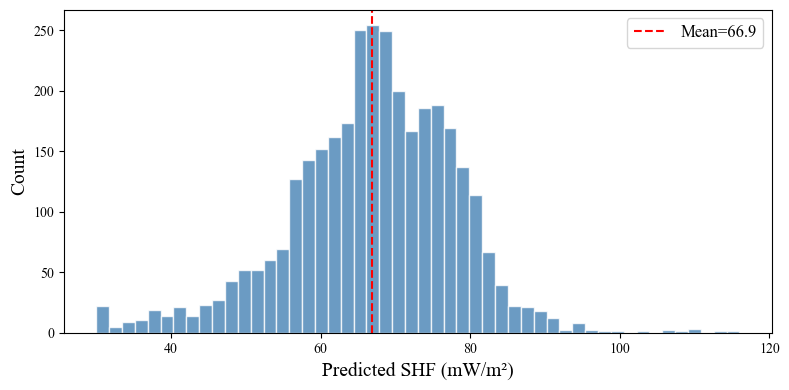

  Upsampled prediction grid: 2037×3261 pts (bilinear x4)
灰白地形底图: (831, 586)


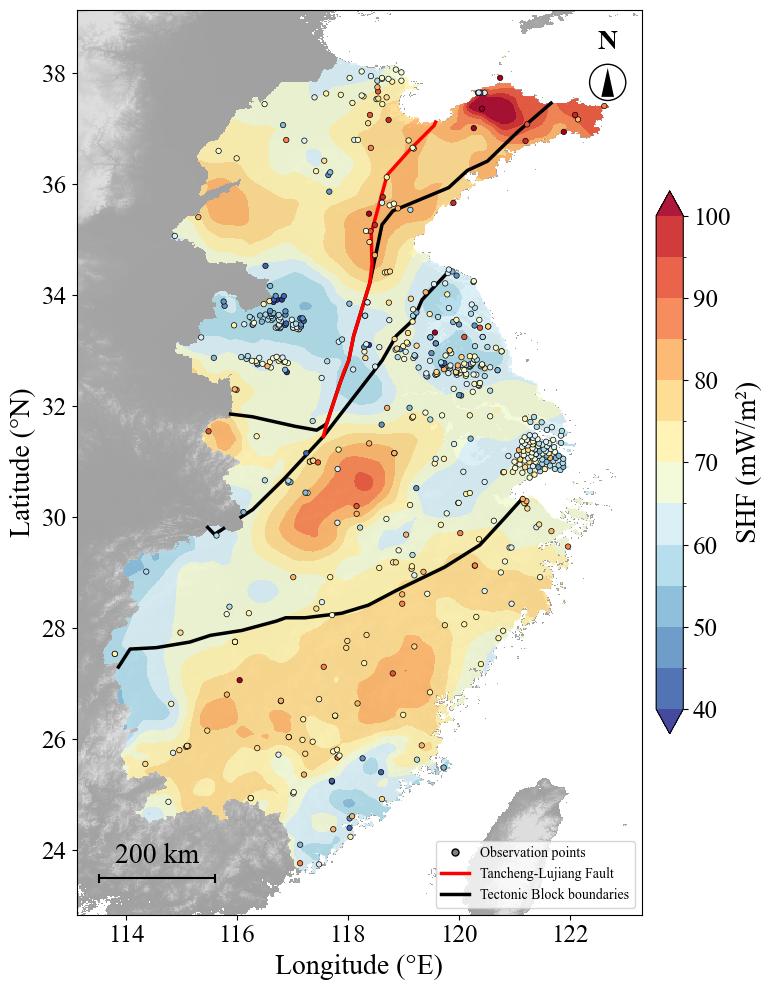

✅ GWR module done


In [8]:
# ==================== GWR 可视化 ====================
out_gwr = Path(OUTPUT_DIR) / 'gwr_output'
out_gwr.mkdir(parents=True, exist_ok=True)
bd = gwr_best_data

# --- XY Scatter ---
tr_r2 = r2_score(bd['yt_tr'], bd['yp_tr']); val_r2 = r2_score(bd['yt_val'], bd['yp_val'])
fig,ax=plt.subplots(figsize=(7,6.5))
ax.scatter(bd['yt_tr'],bd['yp_tr'],alpha=0.5,s=14,c='#3498db',label='train')
ax.scatter(bd['yt_val'],bd['yp_val'],alpha=0.7,s=18,c='#e74c3c',label='val')
ap=np.concatenate([bd['yp_tr'],bd['yp_val']]); at=np.concatenate([bd['yt_tr'],bd['yt_val']]); mn,mx=min(ap.min(),at.min()),max(ap.max(),at.max())
ax.plot([mn,mx],[mn,mx],'k--',lw=1.5,label='y = x')
ax.set_xlabel('True SHF (mW/m²)', fontsize=26); ax.set_ylabel('Predicted SHF (mW/m²)', fontsize=26)
ax.tick_params(labelsize=22)
ax.legend(fontsize=22); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(out_gwr/'gwr_scatter.png',dpi=800); plt.close()

# --- Error Map ---
eps = 1e-6
re_tr = np.clip(np.abs((bd['yt_tr']-bd['yp_tr'])/(bd['yt_tr']+eps))*100,0,50)
re_val = np.clip(np.abs((bd['yt_val']-bd['yp_val'])/(bd['yt_val']+eps))*100,0,50)
# 分层设色：色带 0-50%，每 10% 一级
levels_err = np.arange(0, 60, 10)
norm_err = BoundaryNorm(levels_err, ncolors=256, clip=True)
fig, ax = plt.subplots(figsize=(8,10))

# 灰-白地形底图（背景）
draw_gray_terrain(ax, min(bd['lon_tr'].min(),bd['lon_val'].min()), max(bd['lon_tr'].max(),bd['lon_val'].max()),
                  min(bd['lat_tr'].min(),bd['lat_val'].min()), max(bd['lat_tr'].max(),bd['lat_val'].max()))
ax.scatter(bd['lon_tr'],bd['lat_tr'],c=re_tr,cmap='Reds',norm=norm_err,s=10+re_tr*2,alpha=np.clip(0.2+re_tr/100,0.2,1),
               marker='o',ec='black',lw=0.5,label='Train')
sc=ax.scatter(bd['lon_val'],bd['lat_val'],c=re_val,cmap='Reds',norm=norm_err,s=10+re_val*2,alpha=np.clip(0.2+re_val/100,0.2,1),
               marker='^',ec='black',lw=0.5,label='Val')
cbar=plt.colorbar(sc,ax=ax,shrink=0.35); cbar.set_label('Relative Error (%)',fontsize=26); cbar.ax.tick_params(labelsize=22)
ax.set_xlabel('Longitude (°E)',fontsize=26); ax.set_ylabel('Latitude (°N)',fontsize=26)
ax.tick_params(labelsize=22); ax.legend(loc='lower right',fontsize=22); ax.grid(alpha=0.3)
ax.set_xlim(min(bd['lon_tr'].min(),bd['lon_val'].min())-0.5, max(bd['lon_tr'].max(),bd['lon_val'].max())+0.5)
ax.set_ylim(min(bd['lat_tr'].min(),bd['lat_val'].min())-0.3, max(bd['lat_tr'].max(),bd['lat_val'].max())+0.3)
ax.set_aspect('equal', adjustable='box')
plot_bdy(ax, SHAPEFILE, 'none', 1.2)
add_scale_bar_line(ax); add_north_arrow(ax)
plt.tight_layout(); plt.savefig(out_gwr/'gwr_error_map.png',dpi=800,bbox_inches='tight'); plt.close()

# --- Prediction Raster（使用最佳折的训练集，与原始gwr.py一致） ---
X_pred_gwr_raw, _ = load_features(df_pred, gwr_features)
X_pred_gwr = scaler_X_gwr.transform(X_pred_gwr_raw)
# 使用最佳折的训练数据做最终预测
X_train_best = X_gwr[gwr_best_train_idx]
y_train_best = y_gwr[gwr_best_train_idx]
coords_train_best = coords_train[gwr_best_train_idx]
y_pred_gwr_s = gwr_predict(coords_train_best, X_train_best, y_train_best, coords_pred, X_pred_gwr, bandwidth_gwr, reg=GWR_REG)
y_pred_gwr = scaler_y_gwr.inverse_transform(y_pred_gwr_s.reshape(-1,1)).flatten()
y_pred_gwr = np.clip(y_pred_gwr, 30, 150)
# 数据支撑掩膜：距最近训练台站 > GWR_MASK_DEG 的点不做外推（置 NaN）
_dist_min = cdist(coords_pred, coords_train).min(axis=1)
_support = _dist_min <= GWR_MASK_DEG
print(f'GWR data support: {_support.sum()}/{len(_support)} 点有支撑，掩膜 {(~_support).sum()} 点')
y_pred_gwr = np.where(_support, y_pred_gwr, np.nan)
_valid = ~np.isnan(y_pred_gwr)
print(f'GWR predictions: range=[{np.nanmin(y_pred_gwr):.1f}, {np.nanmax(y_pred_gwr):.1f}], mean={np.nanmean(y_pred_gwr):.1f}')
fig_h, ax_h = plt.subplots(figsize=(8,4))
ax_h.hist(y_pred_gwr[_valid], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
ax_h.set_xlabel('Predicted SHF (mW/m²)', fontsize=14); ax_h.set_ylabel('Count', fontsize=14)
ax_h.axvline(np.nanmean(y_pred_gwr), color='red', ls='--', label=f'Mean={np.nanmean(y_pred_gwr):.1f}')
ax_h.legend(fontsize=12); plt.tight_layout(); plt.savefig(out_gwr/'gwr_hist.png',dpi=800,bbox_inches='tight'); plt.show()

x_p, y_p = df_pred['Lon'].values, df_pred['Lat'].values
xmin,xmax,ymin,ymax = get_ext(SHAPEFILE, df_pred)
xi = np.arange(xmin,xmax,0.02); yi = np.arange(ymin,ymax,0.02)
Xg_g,Yg_g = np.meshgrid(xi,yi)
# ---- 局部克里金插值（AEQD 投影 + 邻域搜索，接近 ArcGIS）----
shf_levels = np.arange(40, 105, 5)
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')

Zg = krige_interp(x_p[_valid], y_p[_valid], y_pred_gwr[_valid], xi, yi, mask_poly)
# 若克里金产生 NaN（极少见），先用最近邻填补，避免上采样产生空洞
if np.isnan(Zg).any():
    from scipy import ndimage
    _idx = ndimage.distance_transform_edt(np.isnan(Zg), return_distances=False, return_indices=True)
    Zg = Zg[tuple(_idx)]
inside_grid = None
if mask_poly:
    pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
    inside_grid = np.array([mask_poly.contains(Point(px, py)) for px, py in pts]).reshape(Xg_g.shape)

# ---- 克里金完成后，用双线性插值细化到更高分辨率（预测栅格图） ----
from scipy.interpolate import RegularGridInterpolator
UPSAMPLE = 4  # 细分倍数：每个粗网格单元格拆成 UPSAMPLE×UPSAMPLE
xi_hi = np.linspace(xi[0], xi[-1], (len(xi) - 1) * UPSAMPLE + 1)
yi_hi = np.linspace(yi[0], yi[-1], (len(yi) - 1) * UPSAMPLE + 1)
Xg_hi, Yg_hi = np.meshgrid(xi_hi, yi_hi)
_rgi = RegularGridInterpolator((yi, xi), Zg, method='linear',
                               bounds_error=False, fill_value=np.nan)
Zg_hi = _rgi((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
if inside_grid is not None:
    _rgi_mask = RegularGridInterpolator((yi, xi), inside_grid.astype(float),
                                        method='linear', bounds_error=False, fill_value=0.0)
    _in_hi = _rgi_mask((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape) >= 0.5
    Zg_hi[~_in_hi] = np.nan
print(f"  Upsampled prediction grid: {len(xi_hi)}×{len(yi_hi)} pts (bilinear x{UPSAMPLE})")

# 训练点中落在研究区内的部分
train_in = np.array([mask_poly.contains(Point(lon, lat)) for lon, lat in zip(df_train['Lon'], df_train['Lat'])]) if mask_poly else np.ones(len(df_train), dtype=bool)

fig, ax = plt.subplots(figsize=(8, 10))
draw_gray_terrain(ax, xmin, xmax, ymin, ymax)   # 灰-白地形底图（背景）
mesh = ax.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9)
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)
ax.scatter(df_train.loc[train_in, 'Lon'].values, df_train.loc[train_in, 'Lat'].values,
           c=y_train[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax, SHAPEFILE, 'none', 1.2)
plot_tectonic_bdy(ax)
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.tick_params(labelsize=18)
obs_h = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_h] + tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, 200, fontsize=20)
add_north_arrow(ax, 0.02, 20)
plt.tight_layout()
plt.savefig(out_gwr/'gwr_prediction_raster.png', dpi=800, bbox_inches='tight')
plt.show()
print(f'✅ GWR module done')

---
## Module 2: Kriging (Ordinary Kriging)

In [9]:
# ==================== Kriging 核心函数 ====================
from pykrige.ok import OrdinaryKriging

def kriging_predict(coords_train, y_train, coords_test, variogram_model='spherical', nlags=6):
    ok = OrdinaryKriging(coords_train[:,0],coords_train[:,1],y_train,
                         variogram_model=variogram_model,nlags=nlags,verbose=False,enable_plotting=False)
    z_pred, _ = ok.execute('points', coords_test[:,0], coords_test[:,1])
    return z_pred

# Kriging 仅使用坐标，不需要特征
print(f'Kriging: using coordinates only, variogram={VARIAGRAM_MODEL}, nlags={NLAGS}')

Kriging: using coordinates only, variogram=spherical, nlags=6


In [10]:
# ==================== Kriging 交叉验证 ====================
kf = KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
krig_fold_results = []
krig_best_r2 = -np.inf
krig_best_fold = None
krig_best_data = None

for fold, (train_idx, val_idx) in enumerate(kf.split(coords_train), 1):
    c_tr, y_tr = coords_train[train_idx], y_train[train_idx]
    c_val, y_val = coords_train[val_idx], y_train[val_idx]
    
    yp_val = kriging_predict(c_tr, y_tr, c_val, VARIAGRAM_MODEL, NLAGS)
    yp_tr = kriging_predict(c_tr, y_tr, c_tr, VARIAGRAM_MODEL, NLAGS)
    
    val_r2 = r2_score(y_val, yp_val)
    val_mse = mean_squared_error(y_val, yp_val)
    val_rmse = np.sqrt(val_mse)
    tr_r2 = r2_score(y_tr, yp_tr)
    tr_mse = mean_squared_error(y_tr, yp_tr)
    tr_rmse = np.sqrt(tr_mse)
    
    print(f'Fold {fold}: Val R²={val_r2:.4f}  Val MSE={val_mse:.2f}  Val RMSE={val_rmse:.2f} | Train R²={tr_r2:.4f}  Train MSE={tr_mse:.2f}  Train RMSE={tr_rmse:.2f}')
    
    data = {
        'fold': fold, 'yt_tr': y_tr, 'yp_tr': yp_tr, 'yt_val': y_val, 'yp_val': yp_val,
        'lon_tr': df_train.iloc[train_idx]['Lon'].values,
        'lat_tr': df_train.iloc[train_idx]['Lat'].values,
        'lon_val': df_train.iloc[val_idx]['Lon'].values,
        'lat_val': df_train.iloc[val_idx]['Lat'].values,
    }
    krig_fold_results.append({'fold':fold,'val_r2':val_r2,'val_mse':val_mse,'tr_r2':tr_r2,'data':data})
    if val_r2 > krig_best_r2:
        krig_best_r2 = val_r2; krig_best_fold = fold; krig_best_data = data

krig_r2_vals = [r['val_r2'] for r in krig_fold_results]
print(f'\nKriging CV: Mean R²={np.mean(krig_r2_vals):.4f} ± {np.std(krig_r2_vals):.4f} | Best Fold {krig_best_fold} R²={krig_best_r2:.4f}')

Fold 1: Val R²=0.2875  Val MSE=187.34  Val RMSE=13.69 | Train R²=0.9777  Train MSE=3.54  Train RMSE=1.88
Fold 2: Val R²=0.1810  Val MSE=94.97  Val RMSE=9.75 | Train R²=0.9607  Train MSE=6.89  Train RMSE=2.62
Fold 3: Val R²=0.3942  Val MSE=99.79  Val RMSE=9.99 | Train R²=0.9503  Train MSE=8.45  Train RMSE=2.91
Fold 4: Val R²=0.0519  Val MSE=236.59  Val RMSE=15.38 | Train R²=0.9488  Train MSE=8.20  Train RMSE=2.86
Fold 5: Val R²=0.1992  Val MSE=109.64  Val RMSE=10.47 | Train R²=0.9517  Train MSE=8.35  Train RMSE=2.89
Fold 6: Val R²=0.0596  Val MSE=90.08  Val RMSE=9.49 | Train R²=0.9494  Train MSE=8.98  Train RMSE=3.00
Fold 7: Val R²=0.2383  Val MSE=88.07  Val RMSE=9.38 | Train R²=0.9719  Train MSE=4.93  Train RMSE=2.22
Fold 8: Val R²=0.2292  Val MSE=163.24  Val RMSE=12.78 | Train R²=0.9634  Train MSE=6.03  Train RMSE=2.45
Fold 9: Val R²=0.1555  Val MSE=131.38  Val RMSE=11.46 | Train R²=0.9609  Train MSE=6.68  Train RMSE=2.58
Fold 10: Val R²=0.2679  Val MSE=127.48  Val RMSE=11.29 | Train 

灰白地形底图: (811, 550)
Kriging predictions: range=[41.6, 87.1], mean=67.8


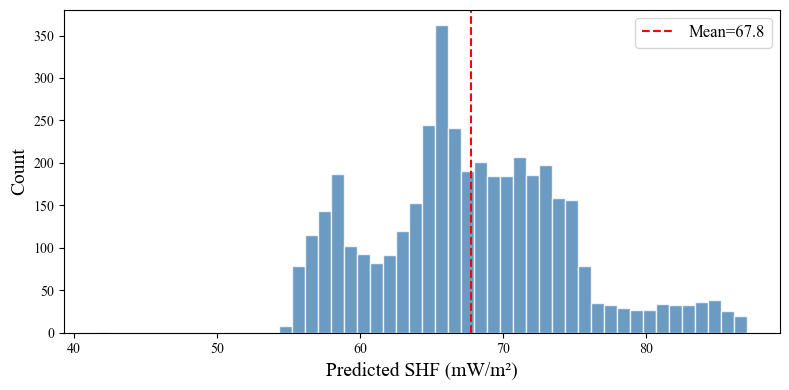

  Upsampled prediction grid: 2037×3261 pts (bilinear x4)
灰白地形底图: (831, 586)


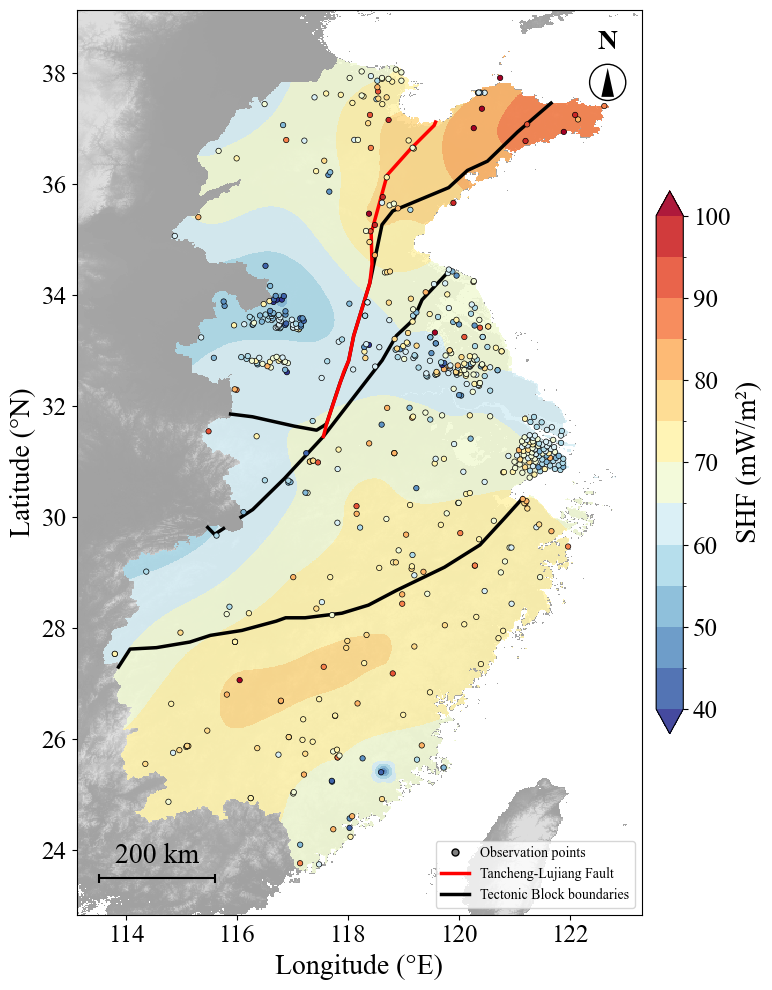

✅ Kriging module done


In [11]:
# ==================== Kriging 可视化 ====================
out_krig = Path(OUTPUT_DIR) / 'kriging_output'
out_krig.mkdir(parents=True, exist_ok=True)
bd = krig_best_data

# --- XY Scatter ---
tr_r2 = r2_score(bd['yt_tr'], bd['yp_tr']); val_r2 = r2_score(bd['yt_val'], bd['yp_val'])
fig,ax=plt.subplots(figsize=(7,6.5))
ax.scatter(bd['yt_tr'],bd['yp_tr'],alpha=0.5,s=14,c='#3498db',label='train')
ax.scatter(bd['yt_val'],bd['yp_val'],alpha=0.7,s=18,c='#e74c3c',label='val')
ap=np.concatenate([bd['yp_tr'],bd['yp_val']]); at=np.concatenate([bd['yt_tr'],bd['yt_val']]); mn,mx=min(ap.min(),at.min()),max(ap.max(),at.max())
ax.plot([mn,mx],[mn,mx],'k--',lw=1.5,label='y = x')
ax.set_xlabel('True SHF (mW/m²)', fontsize=26); ax.set_ylabel('Predicted SHF (mW/m²)', fontsize=26)
ax.tick_params(labelsize=22)
ax.legend(fontsize=22); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(out_krig/'kriging_scatter.png',dpi=800); plt.close()

# --- Error Map ---
eps = 1e-6
re_tr = np.clip(np.abs((bd['yt_tr']-bd['yp_tr'])/(bd['yt_tr']+eps))*100,0,50)
re_val = np.clip(np.abs((bd['yt_val']-bd['yp_val'])/(bd['yt_val']+eps))*100,0,50)
# 分层设色：色带 0-50%，每 10% 一级
levels_err = np.arange(0, 60, 10)
norm_err = BoundaryNorm(levels_err, ncolors=256, clip=True)
fig, ax = plt.subplots(figsize=(8,10))

# 灰-白地形底图（背景）
draw_gray_terrain(ax, min(bd['lon_tr'].min(),bd['lon_val'].min()), max(bd['lon_tr'].max(),bd['lon_val'].max()),
                  min(bd['lat_tr'].min(),bd['lat_val'].min()), max(bd['lat_tr'].max(),bd['lat_val'].max()))
ax.scatter(bd['lon_tr'],bd['lat_tr'],c=re_tr,cmap='Reds',norm=norm_err,s=10+re_tr*2,alpha=np.clip(0.2+re_tr/100,0.2,1),
               marker='o',ec='black',lw=0.5,label='Train')
sc=ax.scatter(bd['lon_val'],bd['lat_val'],c=re_val,cmap='Reds',norm=norm_err,s=10+re_val*2,alpha=np.clip(0.2+re_val/100,0.2,1),
               marker='^',ec='black',lw=0.5,label='Val')
cbar=plt.colorbar(sc,ax=ax,shrink=0.35); cbar.set_label('Relative Error (%)',fontsize=26); cbar.ax.tick_params(labelsize=22)
ax.set_xlabel('Longitude (°E)',fontsize=26); ax.set_ylabel('Latitude (°N)',fontsize=26)
ax.tick_params(labelsize=22); ax.legend(loc='lower right',fontsize=22); ax.grid(alpha=0.3)
ax.set_xlim(min(bd['lon_tr'].min(),bd['lon_val'].min())-0.5, max(bd['lon_tr'].max(),bd['lon_val'].max())+0.5)
ax.set_ylim(min(bd['lat_tr'].min(),bd['lat_val'].min())-0.3, max(bd['lat_tr'].max(),bd['lat_val'].max())+0.3)
ax.set_aspect('equal', adjustable='box')
plot_bdy(ax, SHAPEFILE, 'none', 1.2)
add_scale_bar_line(ax); add_north_arrow(ax)
plt.tight_layout(); plt.savefig(out_krig/'kriging_error_map.png',dpi=800,bbox_inches='tight'); plt.close()

# --- Prediction Raster ---
y_pred_krig = kriging_predict(coords_train, y_train, coords_pred, VARIAGRAM_MODEL, NLAGS)
y_pred_krig = np.clip(y_pred_krig, 30, 150)
print(f'Kriging predictions: range=[{y_pred_krig.min():.1f}, {y_pred_krig.max():.1f}], mean={y_pred_krig.mean():.1f}')
fig_h, ax_h = plt.subplots(figsize=(8,4))
ax_h.hist(y_pred_krig, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
ax_h.set_xlabel('Predicted SHF (mW/m²)', fontsize=14); ax_h.set_ylabel('Count', fontsize=14)
ax_h.axvline(y_pred_krig.mean(), color='red', ls='--', label=f'Mean={y_pred_krig.mean():.1f}')
ax_h.legend(fontsize=12); plt.tight_layout(); plt.savefig(out_krig/'kriging_hist.png',dpi=800,bbox_inches='tight'); plt.show()

# ---- 局部克里金插值（AEQD 投影 + 邻域搜索，接近 ArcGIS）----
shf_levels = np.arange(40, 105, 5)
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')

Zg = krige_interp(x_p, y_p, y_pred_krig, xi, yi, mask_poly)
# 若克里金产生 NaN（极少见），先用最近邻填补，避免上采样产生空洞
if np.isnan(Zg).any():
    from scipy import ndimage
    _idx = ndimage.distance_transform_edt(np.isnan(Zg), return_distances=False, return_indices=True)
    Zg = Zg[tuple(_idx)]
inside_grid = None
if mask_poly:
    pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
    inside_grid = np.array([mask_poly.contains(Point(px, py)) for px, py in pts]).reshape(Xg_g.shape)

# ---- 克里金完成后，用双线性插值细化到更高分辨率（预测栅格图） ----
from scipy.interpolate import RegularGridInterpolator
UPSAMPLE = 4  # 细分倍数：每个粗网格单元格拆成 UPSAMPLE×UPSAMPLE
xi_hi = np.linspace(xi[0], xi[-1], (len(xi) - 1) * UPSAMPLE + 1)
yi_hi = np.linspace(yi[0], yi[-1], (len(yi) - 1) * UPSAMPLE + 1)
Xg_hi, Yg_hi = np.meshgrid(xi_hi, yi_hi)
_rgi = RegularGridInterpolator((yi, xi), Zg, method='linear',
                               bounds_error=False, fill_value=np.nan)
Zg_hi = _rgi((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
if inside_grid is not None:
    _rgi_mask = RegularGridInterpolator((yi, xi), inside_grid.astype(float),
                                        method='linear', bounds_error=False, fill_value=0.0)
    _in_hi = _rgi_mask((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape) >= 0.5
    Zg_hi[~_in_hi] = np.nan
print(f"  Upsampled prediction grid: {len(xi_hi)}×{len(yi_hi)} pts (bilinear x{UPSAMPLE})")

# 训练点中落在研究区内的部分
train_in = np.array([mask_poly.contains(Point(lon, lat)) for lon, lat in zip(df_train['Lon'], df_train['Lat'])]) if mask_poly else np.ones(len(df_train), dtype=bool)

fig, ax = plt.subplots(figsize=(8, 10))
draw_gray_terrain(ax, xmin, xmax, ymin, ymax)   # 灰-白地形底图（背景）
mesh = ax.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9)
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)
ax.scatter(df_train.loc[train_in, 'Lon'].values, df_train.loc[train_in, 'Lat'].values,
           c=y_train[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax, SHAPEFILE, 'none', 1.2)
plot_tectonic_bdy(ax)
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.tick_params(labelsize=18)
obs_h = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_h] + tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, 200, fontsize=20)
add_north_arrow(ax, 0.02, 20)
plt.tight_layout()
plt.savefig(out_krig/'kriging_prediction_raster.png', dpi=800, bbox_inches='tight')
plt.show()
print(f'✅ Kriging module done')

---
## Module 3: XGBoost

In [12]:
# ==================== XGBoost 核心 ====================
import xgboost as xgb

# XGBoost 使用含 Lon/Lat 的特征列
X_xgb_raw, xgb_features = load_features(df_train, GEO_COLS_XGB)
print(f'XGBoost: {len(xgb_features)} features')

XGBoost: 13 features


In [13]:
# ==================== XGBoost 交叉验证 ====================
kf = KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
xgb_fold_results = []
xgb_best_r2 = -np.inf
xgb_best_fold = None
xgb_best_data = None
xgb_best_model = None

for fold, (train_idx, val_idx) in enumerate(kf.split(X_xgb_raw), 1):
    X_tr, y_tr = X_xgb_raw[train_idx], y_train[train_idx]
    X_val, y_val = X_xgb_raw[val_idx], y_train[val_idx]
    
    model = xgb.XGBRegressor(**XGB_PARAMS, n_jobs=-1)
    model.fit(X_tr, y_tr, eval_set=[(X_val,y_val)], verbose=False)
    
    yp_val = model.predict(X_val)
    yp_tr = model.predict(X_tr)
    
    val_r2 = r2_score(y_val, yp_val)
    val_mse = mean_squared_error(y_val, yp_val)
    val_rmse = np.sqrt(val_mse)
    tr_r2 = r2_score(y_tr, yp_tr)
    tr_mse = mean_squared_error(y_tr, yp_tr)
    tr_rmse = np.sqrt(tr_mse)
    
    print(f'Fold {fold}: Val R²={val_r2:.4f}  Val MSE={val_mse:.2f}  Val RMSE={val_rmse:.2f} | Train R²={tr_r2:.4f}  Train MSE={tr_mse:.2f}  Train RMSE={tr_rmse:.2f}')
    
    data = {
        'fold': fold, 'yt_tr': y_tr, 'yp_tr': yp_tr, 'yt_val': y_val, 'yp_val': yp_val,
        'lon_tr': df_train.iloc[train_idx]['Lon'].values,
        'lat_tr': df_train.iloc[train_idx]['Lat'].values,
        'lon_val': df_train.iloc[val_idx]['Lon'].values,
        'lat_val': df_train.iloc[val_idx]['Lat'].values,
    }
    xgb_fold_results.append({'fold':fold,'val_r2':val_r2,'val_mse':val_mse,'tr_r2':tr_r2,'data':data})
    if val_r2 > xgb_best_r2:
        xgb_best_r2 = val_r2; xgb_best_fold = fold; xgb_best_data = data; xgb_best_model = model

xgb_r2_vals = [r['val_r2'] for r in xgb_fold_results]
print(f'\nXGBoost CV: Mean R²={np.mean(xgb_r2_vals):.4f} ± {np.std(xgb_r2_vals):.4f} | Best Fold {xgb_best_fold} R²={xgb_best_r2:.4f}')

Fold 1: Val R²=0.4006  Val MSE=157.60  Val RMSE=12.55 | Train R²=0.9877  Train MSE=1.96  Train RMSE=1.40
Fold 2: Val R²=-0.0021  Val MSE=116.20  Val RMSE=10.78 | Train R²=0.9890  Train MSE=1.94  Train RMSE=1.39
Fold 3: Val R²=0.5492  Val MSE=74.26  Val RMSE=8.62 | Train R²=0.9868  Train MSE=2.24  Train RMSE=1.50
Fold 4: Val R²=-0.0119  Val MSE=252.50  Val RMSE=15.89 | Train R²=0.9864  Train MSE=2.17  Train RMSE=1.47
Fold 5: Val R²=0.2632  Val MSE=100.88  Val RMSE=10.04 | Train R²=0.9879  Train MSE=2.09  Train RMSE=1.45
Fold 6: Val R²=-0.1978  Val MSE=114.74  Val RMSE=10.71 | Train R²=0.9896  Train MSE=1.84  Train RMSE=1.36
Fold 7: Val R²=0.1451  Val MSE=98.85  Val RMSE=9.94 | Train R²=0.9921  Train MSE=1.39  Train RMSE=1.18
Fold 8: Val R²=0.2751  Val MSE=153.52  Val RMSE=12.39 | Train R²=0.9880  Train MSE=1.98  Train RMSE=1.41
Fold 9: Val R²=0.4074  Val MSE=92.19  Val RMSE=9.60 | Train R²=0.9893  Train MSE=1.83  Train RMSE=1.35
Fold 10: Val R²=0.2631  Val MSE=128.32  Val RMSE=11.33 | T

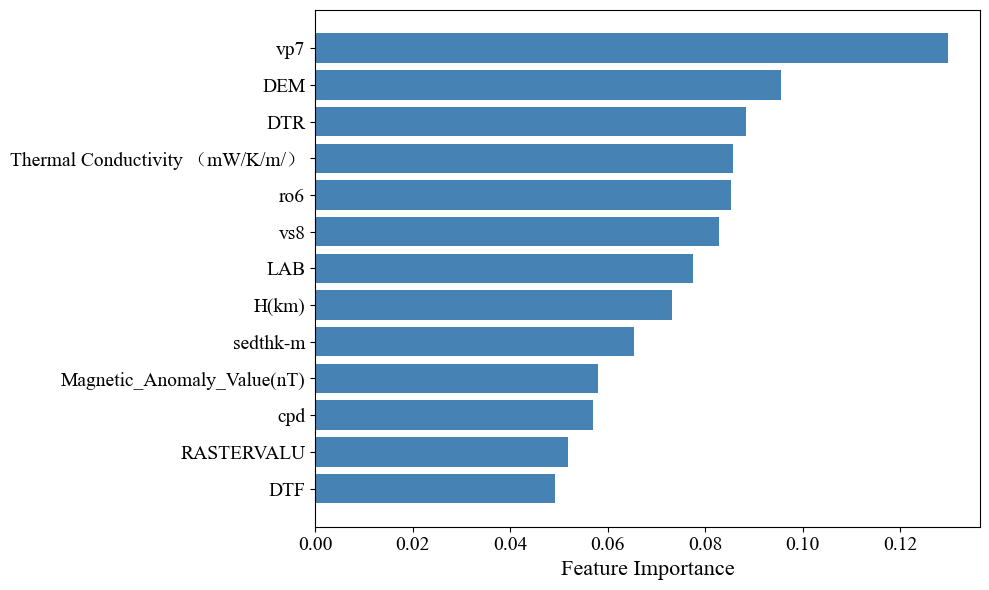

灰白地形底图: (811, 550)
XGBoost predictions: range=[44.5, 108.3], mean=69.8


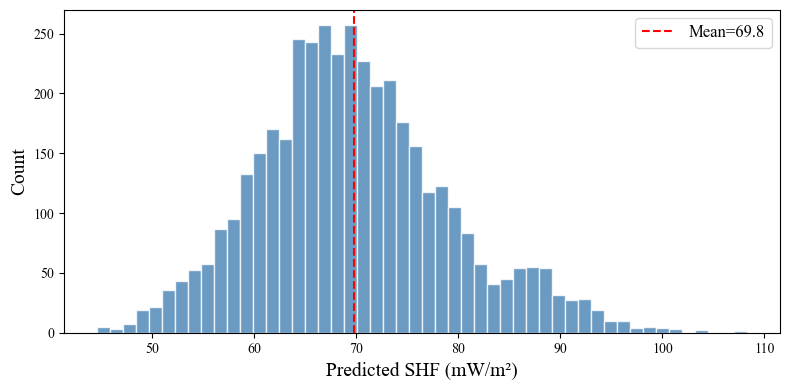

  Upsampled prediction grid: 2037×3261 pts (bilinear x4)
灰白地形底图: (831, 586)


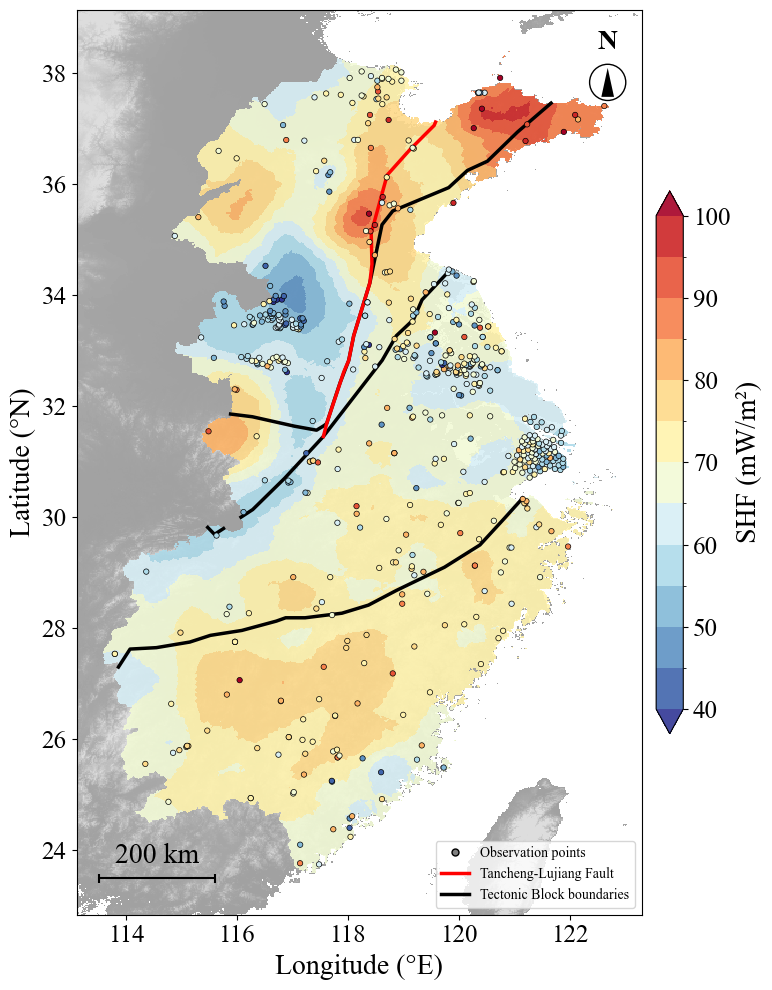

✅ XGBoost module done


In [14]:
# ==================== XGBoost 可视化 ====================
out_xgb = Path(OUTPUT_DIR) / 'xgboost_output'
out_xgb.mkdir(parents=True, exist_ok=True)
bd = xgb_best_data

# --- XY Scatter ---
tr_r2 = r2_score(bd['yt_tr'], bd['yp_tr']); val_r2 = r2_score(bd['yt_val'], bd['yp_val'])
fig,ax=plt.subplots(figsize=(7,6.5))
ax.scatter(bd['yt_tr'],bd['yp_tr'],alpha=0.5,s=14,c='#3498db',label='train')
ax.scatter(bd['yt_val'],bd['yp_val'],alpha=0.7,s=18,c='#e74c3c',label='val')
ap=np.concatenate([bd['yp_tr'],bd['yp_val']]); at=np.concatenate([bd['yt_tr'],bd['yt_val']]); mn,mx=min(ap.min(),at.min()),max(ap.max(),at.max())
ax.plot([mn,mx],[mn,mx],'k--',lw=1.5,label='y = x')
ax.set_xlabel('True SHF (mW/m²)', fontsize=26); ax.set_ylabel('Predicted SHF (mW/m²)', fontsize=26)
ax.tick_params(labelsize=22)
ax.legend(fontsize=22); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(out_xgb/'xgboost_scatter.png',dpi=800); plt.close()

# --- Feature Importance ---
importance = xgb_best_model.feature_importances_
idx = np.argsort(importance)[::-1][:20]
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(range(len(idx)), importance[idx][::-1], color='steelblue')
ax.set_yticks(range(len(idx)))
ax.set_yticklabels([xgb_features[i] for i in idx][::-1], fontsize=14)
ax.set_xlabel('Feature Importance',fontsize=16); ax.tick_params(labelsize=14)
plt.tight_layout(); plt.savefig(out_xgb/'xgboost_feature_importance.png',dpi=800,bbox_inches='tight'); plt.show()

# --- Error Map ---
eps = 1e-6
re_tr = np.clip(np.abs((bd['yt_tr']-bd['yp_tr'])/(bd['yt_tr']+eps))*100,0,50)
re_val = np.clip(np.abs((bd['yt_val']-bd['yp_val'])/(bd['yt_val']+eps))*100,0,50)
# 分层设色：色带 0-50%，每 10% 一级
levels_err = np.arange(0, 60, 10)
norm_err = BoundaryNorm(levels_err, ncolors=256, clip=True)
fig, ax = plt.subplots(figsize=(8,10))

# 灰-白地形底图（背景）
draw_gray_terrain(ax, min(bd['lon_tr'].min(),bd['lon_val'].min()), max(bd['lon_tr'].max(),bd['lon_val'].max()),
                  min(bd['lat_tr'].min(),bd['lat_val'].min()), max(bd['lat_tr'].max(),bd['lat_val'].max()))
ax.scatter(bd['lon_tr'],bd['lat_tr'],c=re_tr,cmap='Reds',norm=norm_err,s=10+re_tr*2,alpha=np.clip(0.2+re_tr/100,0.2,1),
               marker='o',ec='black',lw=0.5,label='Train')
sc=ax.scatter(bd['lon_val'],bd['lat_val'],c=re_val,cmap='Reds',norm=norm_err,s=10+re_val*2,alpha=np.clip(0.2+re_val/100,0.2,1),
               marker='^',ec='black',lw=0.5,label='Val')
cbar=plt.colorbar(sc,ax=ax,shrink=0.35); cbar.set_label('Relative Error (%)',fontsize=26); cbar.ax.tick_params(labelsize=22)
ax.set_xlabel('Longitude (°E)',fontsize=26); ax.set_ylabel('Latitude (°N)',fontsize=26)
ax.tick_params(labelsize=22); ax.legend(loc='lower right',fontsize=22); ax.grid(alpha=0.3)
ax.set_xlim(min(bd['lon_tr'].min(),bd['lon_val'].min())-0.5, max(bd['lon_tr'].max(),bd['lon_val'].max())+0.5)
ax.set_ylim(min(bd['lat_tr'].min(),bd['lat_val'].min())-0.3, max(bd['lat_tr'].max(),bd['lat_val'].max())+0.3)
ax.set_aspect('equal', adjustable='box')
plot_bdy(ax, SHAPEFILE, 'none', 1.2)
add_scale_bar_line(ax); add_north_arrow(ax)
plt.tight_layout(); plt.savefig(out_xgb/'xgboost_error_map.png',dpi=800,bbox_inches='tight'); plt.close()

# --- Prediction Raster ---
X_pred_xgb_raw, _ = load_features(df_pred, xgb_features)
y_pred_xgb = xgb_best_model.predict(X_pred_xgb_raw)
y_pred_xgb = np.clip(y_pred_xgb, 30, 150)
print(f'XGBoost predictions: range=[{y_pred_xgb.min():.1f}, {y_pred_xgb.max():.1f}], mean={y_pred_xgb.mean():.1f}')
fig_h, ax_h = plt.subplots(figsize=(8,4))
ax_h.hist(y_pred_xgb, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
ax_h.set_xlabel('Predicted SHF (mW/m²)', fontsize=14); ax_h.set_ylabel('Count', fontsize=14)
ax_h.axvline(y_pred_xgb.mean(), color='red', ls='--', label=f'Mean={y_pred_xgb.mean():.1f}')
ax_h.legend(fontsize=12); plt.tight_layout(); plt.savefig(out_xgb/'xgboost_hist.png',dpi=800,bbox_inches='tight'); plt.show()

# ---- 局部克里金插值（AEQD 投影 + 邻域搜索，接近 ArcGIS）----
shf_levels = np.arange(40, 105, 5)
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')

Zg = krige_interp(x_p, y_p, y_pred_xgb, xi, yi, mask_poly)
# 若克里金产生 NaN（极少见），先用最近邻填补，避免上采样产生空洞
if np.isnan(Zg).any():
    from scipy import ndimage
    _idx = ndimage.distance_transform_edt(np.isnan(Zg), return_distances=False, return_indices=True)
    Zg = Zg[tuple(_idx)]
inside_grid = None
if mask_poly:
    pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
    inside_grid = np.array([mask_poly.contains(Point(px, py)) for px, py in pts]).reshape(Xg_g.shape)

# ---- 克里金完成后，用双线性插值细化到更高分辨率（预测栅格图） ----
from scipy.interpolate import RegularGridInterpolator
UPSAMPLE = 4  # 细分倍数：每个粗网格单元格拆成 UPSAMPLE×UPSAMPLE
xi_hi = np.linspace(xi[0], xi[-1], (len(xi) - 1) * UPSAMPLE + 1)
yi_hi = np.linspace(yi[0], yi[-1], (len(yi) - 1) * UPSAMPLE + 1)
Xg_hi, Yg_hi = np.meshgrid(xi_hi, yi_hi)
_rgi = RegularGridInterpolator((yi, xi), Zg, method='linear',
                               bounds_error=False, fill_value=np.nan)
Zg_hi = _rgi((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape)
if inside_grid is not None:
    _rgi_mask = RegularGridInterpolator((yi, xi), inside_grid.astype(float),
                                        method='linear', bounds_error=False, fill_value=0.0)
    _in_hi = _rgi_mask((Yg_hi.ravel(), Xg_hi.ravel())).reshape(Xg_hi.shape) >= 0.5
    Zg_hi[~_in_hi] = np.nan
print(f"  Upsampled prediction grid: {len(xi_hi)}×{len(yi_hi)} pts (bilinear x{UPSAMPLE})")

# 训练点中落在研究区内的部分
train_in = np.array([mask_poly.contains(Point(lon, lat)) for lon, lat in zip(df_train['Lon'], df_train['Lat'])]) if mask_poly else np.ones(len(df_train), dtype=bool)

fig, ax = plt.subplots(figsize=(8, 10))
draw_gray_terrain(ax, xmin, xmax, ymin, ymax)   # 灰-白地形底图（背景）
mesh = ax.pcolormesh(Xg_hi, Yg_hi, Zg_hi, cmap='RdYlBu_r', norm=norm_shf, shading='auto', alpha=0.9)
cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('SHF (mW/m²)', fontsize=20)
cbar.ax.tick_params(labelsize=18)
ax.scatter(df_train.loc[train_in, 'Lon'].values, df_train.loc[train_in, 'Lat'].values,
           c=y_train[train_in], cmap='RdYlBu_r', norm=norm_shf, s=15, ec='k', lw=0.5, zorder=5)
ax.set_xlabel('Longitude (°E)', fontsize=20)
ax.set_ylabel('Latitude (°N)', fontsize=20)
plot_bdy(ax, SHAPEFILE, 'none', 1.2)
plot_tectonic_bdy(ax)
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.tick_params(labelsize=18)
obs_h = Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markeredgecolor='k', markersize=5, label='Observation points')
ax.legend(handles=[obs_h] + tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
add_scale_bar_line(ax, 200, fontsize=20)
add_north_arrow(ax, 0.02, 20)
plt.tight_layout()
plt.savefig(out_xgb/'xgboost_prediction_raster.png', dpi=800, bbox_inches='tight')
plt.show()
print(f'✅ XGBoost module done')

In [15]:
# ==================== 汇总表 ====================
print(f"\n{'='*60}")
print(f"{'Model':<12} {'Mean Val R²':>14} {'Best Fold':>10} {'Best R²':>10}")
print(f"{'-'*50}")
print(f"{'GWR':<12} {np.mean(gwr_r2_vals):>14.4f} {gwr_best_fold:>10} {gwr_best_r2:>10.4f}")
print(f"{'Kriging':<12} {np.mean(krig_r2_vals):>14.4f} {krig_best_fold:>10} {krig_best_r2:>10.4f}")
print(f"{'XGBoost':<12} {np.mean(xgb_r2_vals):>14.4f} {xgb_best_fold:>10} {xgb_best_r2:>10.4f}")
print(f"{'='*60}")

# 输出目录汇总
for name, path in [('GWR',out_gwr),('Kriging',out_krig),('XGBoost',out_xgb)]:
    files = list(path.glob('*.png'))
    print(f'{name}: {len(files)} plots in {path}')
print('\n✅ All modules complete')


Model           Mean Val R²  Best Fold    Best R²
--------------------------------------------------
GWR                  0.2232          3     0.4233
Kriging              0.2064          3     0.3942
XGBoost              0.2092          3     0.5492
GWR: 4 plots in c:\KAN-OLS-SHF\output\train\gwr_output
Kriging: 5 plots in c:\KAN-OLS-SHF\output\train\kriging_output
XGBoost: 6 plots in c:\KAN-OLS-SHF\output\train\xgboost_output

✅ All modules complete


---
## 🔬 RBFKAN 与基线模型差异对比

将 RBFKAN 的 0.2° 网格预测结果与 GWR、Kriging、XGBoost 做差，绘制差值栅格图（仅保留轮廓内区域）。


🔬 RBFKAN 与基线模型差异对比
RBFKAN grid: 4131 points from c:\KAN-OLS-SHF\output\train\rbfkan\point_predictions.csv
统一色带范围: [-60, 60] mW/m²，步长 5，共 24 级（蓝-白-红）


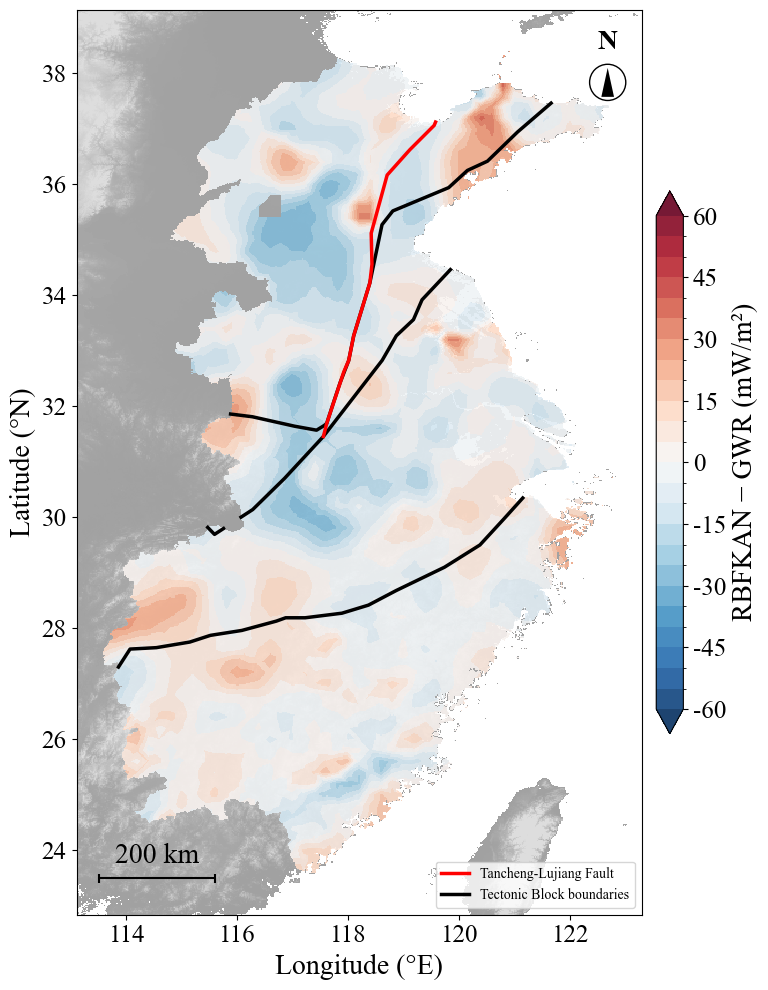

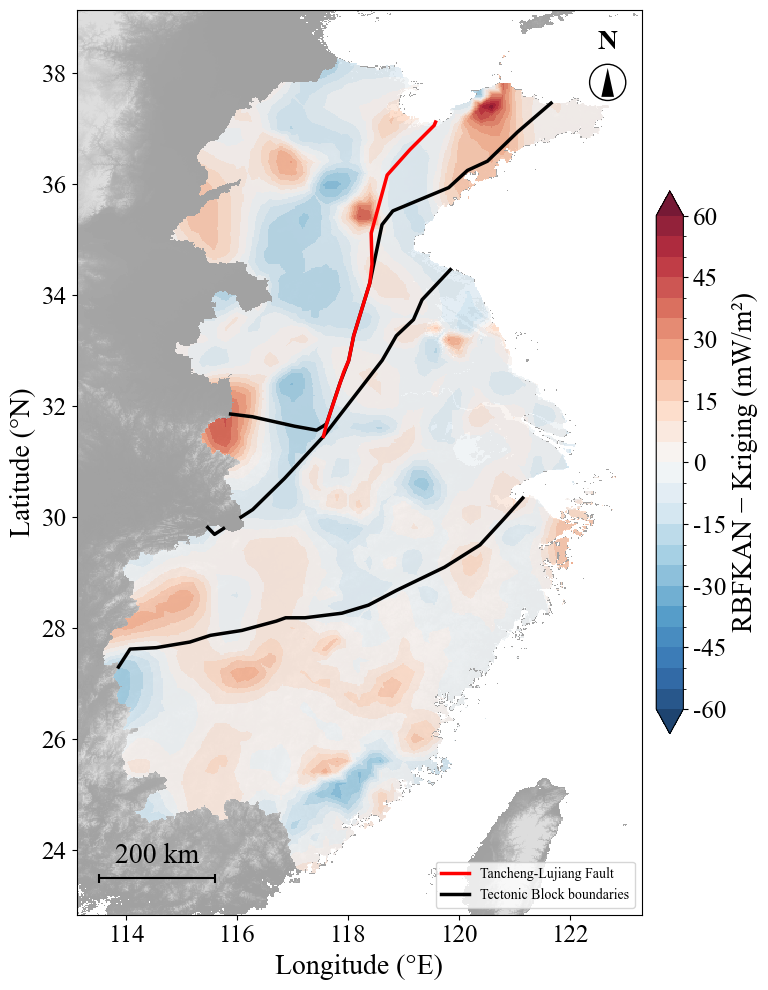

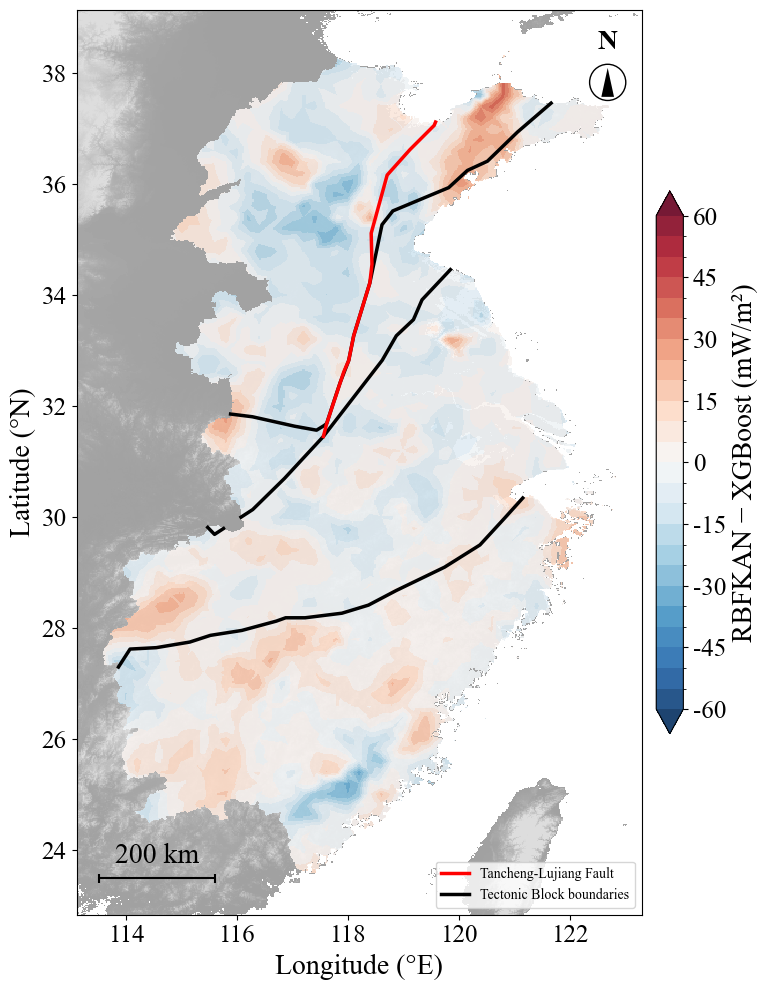

💾 Saved difference grid (188648 points) to c:\KAN-OLS-SHF\output\train\diff_output\RBFKAN_minus_baseline_diff.csv
✅ Difference maps complete


In [16]:
# ==================== RBFKAN vs 基线模型差异栅格图 ====================
print(f"\n{'='*60}\n🔬 RBFKAN 与基线模型差异对比\n{'='*60}")

# 加载 RBFKAN 的 0.2° 网格预测
rbfkan_csv = r'c:\KAN-OLS-SHF\output\train\rbfkan\point_predictions.csv'
rbfkan_df = pd.read_csv(rbfkan_csv)
print(f"RBFKAN grid: {len(rbfkan_df)} points from {rbfkan_csv}")

# 将 RBFKAN 网格插值到统一网格 (Xg_g, Yg_g)
Zg_rbfkan = griddata(
    (rbfkan_df['Lon'].values, rbfkan_df['Lat'].values),
    rbfkan_df['predicted_heat_flow'].values,
    (Xg_g, Yg_g), method='linear'
)

# 重新计算各基线模型的干净网格（不做 mask）
baseline_grids = {}

# GWR 网格（与 GWR 模块一致：岭正则 + 数据支撑掩膜）
X_pred_gwr_raw2, _ = load_features(df_pred, gwr_features)
X_pred_gwr2 = scaler_X_gwr.transform(X_pred_gwr_raw2)
y_pred_gwr2_s = gwr_predict(coords_train_best, X_train_best, y_train_best, coords_pred, X_pred_gwr2, bandwidth_gwr, reg=GWR_REG)
y_pred_gwr2 = scaler_y_gwr.inverse_transform(y_pred_gwr2_s.reshape(-1,1)).flatten()
y_pred_gwr2 = np.where(_dist_min <= GWR_MASK_DEG, y_pred_gwr2, np.nan)
baseline_grids['GWR'] = griddata((x_p, y_p), y_pred_gwr2, (Xg_g, Yg_g), method='linear')

# Kriging 网格
baseline_grids['Kriging'] = griddata((x_p, y_p), y_pred_krig, (Xg_g, Yg_g), method='linear')

# XGBoost 网格
baseline_grids['XGBoost'] = griddata((x_p, y_p), y_pred_xgb, (Xg_g, Yg_g), method='linear')

# 计算差值（先全部算好，便于统一三张图的色带范围）
out_diff = Path(OUTPUT_DIR) / 'diff_output'
out_diff.mkdir(parents=True, exist_ok=True)

diff_data = {'Lon': Xg_g.ravel(), 'Lat': Yg_g.ravel()}
diff_grids = {}

for name, Zg_base in baseline_grids.items():
    Zg_diff = Zg_rbfkan - Zg_base  # RBFKAN - baseline
    # 仅保留轮廓内
    if mask_poly:
        pts = np.column_stack((Xg_g.ravel(), Yg_g.ravel()))
        Zg_diff[~np.array([mask_poly.contains(Point(px,py)) for px,py in pts]).reshape(Xg_g.shape)] = np.nan
    diff_grids[name] = Zg_diff

# ---- 统一色带范围：取三张图整体最大绝对值，圆整到 5 的倍数（三图共用一套等级） ----
_valid_vals = np.concatenate([g[~np.isnan(g)] for g in diff_grids.values()])
if _valid_vals.size == 0:
    _max_abs = 5.0
else:
    _max_abs = float(max(abs(np.nanmin(_valid_vals)), abs(np.nanmax(_valid_vals))))
D = max(float(np.ceil(_max_abs / 5.0) * 5.0), 5.0)
# 分层设色：蓝-白-红 离散等级（负值蓝、0 白、正值红）
levels_diff = np.arange(-D, D + 5, 5)
norm_diff = BoundaryNorm(levels_diff, ncolors=256, extend='both')
print(f"统一色带范围: [{levels_diff[0]:.0f}, {levels_diff[-1]:.0f}] mW/m²，步长 5，共 {len(levels_diff)-1} 级（蓝-白-红）")

for name, Zg_diff in diff_grids.items():
    fig, ax = plt.subplots(figsize=(8,10))
    draw_gray_terrain(ax, xmin, xmax, ymin, ymax)   # 灰-白地形底图（背景）
    mesh = ax.pcolormesh(Xg_g, Yg_g, Zg_diff, cmap='RdBu_r', norm=norm_diff,
                         shading='auto', alpha=0.9)
    cbar = plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
    cbar.set_label(f'RBFKAN − {name} (mW/m²)', fontsize=20)
    cbar.ax.tick_params(labelsize=18)
    
    ax.set_xlabel('Longitude (°E)', fontsize=20)
    ax.set_ylabel('Latitude (°N)', fontsize=20)
    ax.set_aspect('equal', adjustable='box')
    plot_bdy(ax, SHAPEFILE, 'none', 1.2)
    plot_tectonic_bdy(ax)
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.tick_params(labelsize=18)
    
    ax.legend(handles=tectonic_legend_handles, loc='lower right', fontsize=10, framealpha=0.8)
    add_scale_bar_line(ax, 200, fontsize=20)
    add_north_arrow(ax, 0.02, 20)
    
    plt.tight_layout()
    plt.savefig(out_diff / f'RBFKAN_minus_{name}_diff.png', dpi=800, bbox_inches='tight')
    plt.show()
    
    diff_data[f'diff_RBFKAN_minus_{name}'] = Zg_diff.ravel()

# 保存差值 CSV
diff_df = pd.DataFrame(diff_data).dropna()
diff_csv = out_diff / 'RBFKAN_minus_baseline_diff.csv'
diff_df.to_csv(diff_csv, index=False)
print(f'💾 Saved difference grid ({len(diff_df)} points) to {diff_csv}')
print(f'✅ Difference maps complete')